In [60]:
import pandas as pd
import seaborn as sns
import  matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import cohen_kappa_score, make_scorer
import optuna

In [133]:
df = pd.read_csv(r'C:\Users\gupta\Learn\Internship_DecodeLabs\Data\Diamond\Dataset\diamonds.csv')


# Data exploration

In [134]:
df.shape

(53940, 10)

In [135]:
df.head()

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,b'Ideal',b'E',b'SI2',61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,b'Premium',b'E',b'SI1',59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,b'Good',b'E',b'VS1',56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,b'Premium',b'I',b'VS2',62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,b'Good',b'J',b'SI2',63.3,58.0,335.0,4.34,4.35,2.75


In [136]:
df[['cut','color','clarity']]

,cut,color,clarity
0,b'Ideal',b'E',b'SI2'
1,b'Premium',b'E',b'SI1'
2,b'Good',b'E',b'VS1'
3,b'Premium',b'I',b'VS2'
4,b'Good',b'J',b'SI2'
...,...,...,...
53935,b'Ideal',b'D',b'SI1'
53936,b'Good',b'D',b'SI1'
53937,b'Very Good',b'D',b'SI1'
53938,b'Premium',b'H',b'SI2'


In [137]:
cat_cols = ['cut','color','clarity']
for col in cat_cols:
    df[col] = df[col].str.split("'").str[1].astype(str)


In [138]:
df.dtypes

carat      float64
cut            str
color          str
clarity        str
depth      float64
table      float64
price      float64
'x'        float64
'y'        float64
'z'        float64
dtype: object

In [139]:
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
'x'        0
'y'        0
'z'        0
dtype: int64

In [140]:
cols = ["carat", "cut", "color", "clarity", "price"]
df.duplicated(cols).sum()

np.int64(14184)

In [141]:
df[df.duplicated(keep=False)]

,carat,cut,color,clarity,depth,table,price,'x','y','z'
1004,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1005,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1006,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1007,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1008,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
...,...,...,...,...,...,...,...,...,...,...
49557,0.71,Good,F,SI2,64.1,60.0,2130.0,0.00,0.00,0.00
50078,0.51,Ideal,F,VVS2,61.2,56.0,2203.0,5.19,5.17,3.17
50079,0.51,Ideal,F,VVS2,61.2,56.0,2203.0,5.19,5.17,3.17
52860,0.50,Fair,E,VS2,79.0,73.0,2579.0,5.21,5.18,4.09


In [142]:
df = df.drop_duplicates(cols)

In [143]:
df.describe()

,carat,depth,table,price,'x','y','z'
count,39756.000000,39756.000000,39756.000000,39756.000000,39756.000000,39756.000000,39756.000000
mean,0.903571,61.740281,57.575634,4688.161384,6.007941,6.011052,3.709011
std,0.479221,1.533119,2.298224,4201.617572,1.082521,1.105099,0.687200
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.520000,61.000000,56.000000,1410.000000,5.160000,5.170000,3.190000
50%,0.850000,61.800000,57.000000,3369.000000,6.040000,6.040000,3.730000
75%,1.150000,62.600000,59.000000,6409.250000,6.730000,6.720000,4.150000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [144]:
df.shape

(39756, 10)

In [145]:
num_cols = [item for item in list(df.columns) if item not in cat_cols]
num_cols

['carat', 'depth', 'table', 'price', "'x'", "'y'", "'z'"]

In [150]:
cut_ranking = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
y_encoder = OrdinalEncoder(categories=[cut_ranking])
df['cut'] = y_encoder.fit_transform(df[['cut']])

# DATA ANALYSIS

## Distribution

In [36]:
cat_cols

['cut', 'color', 'clarity']

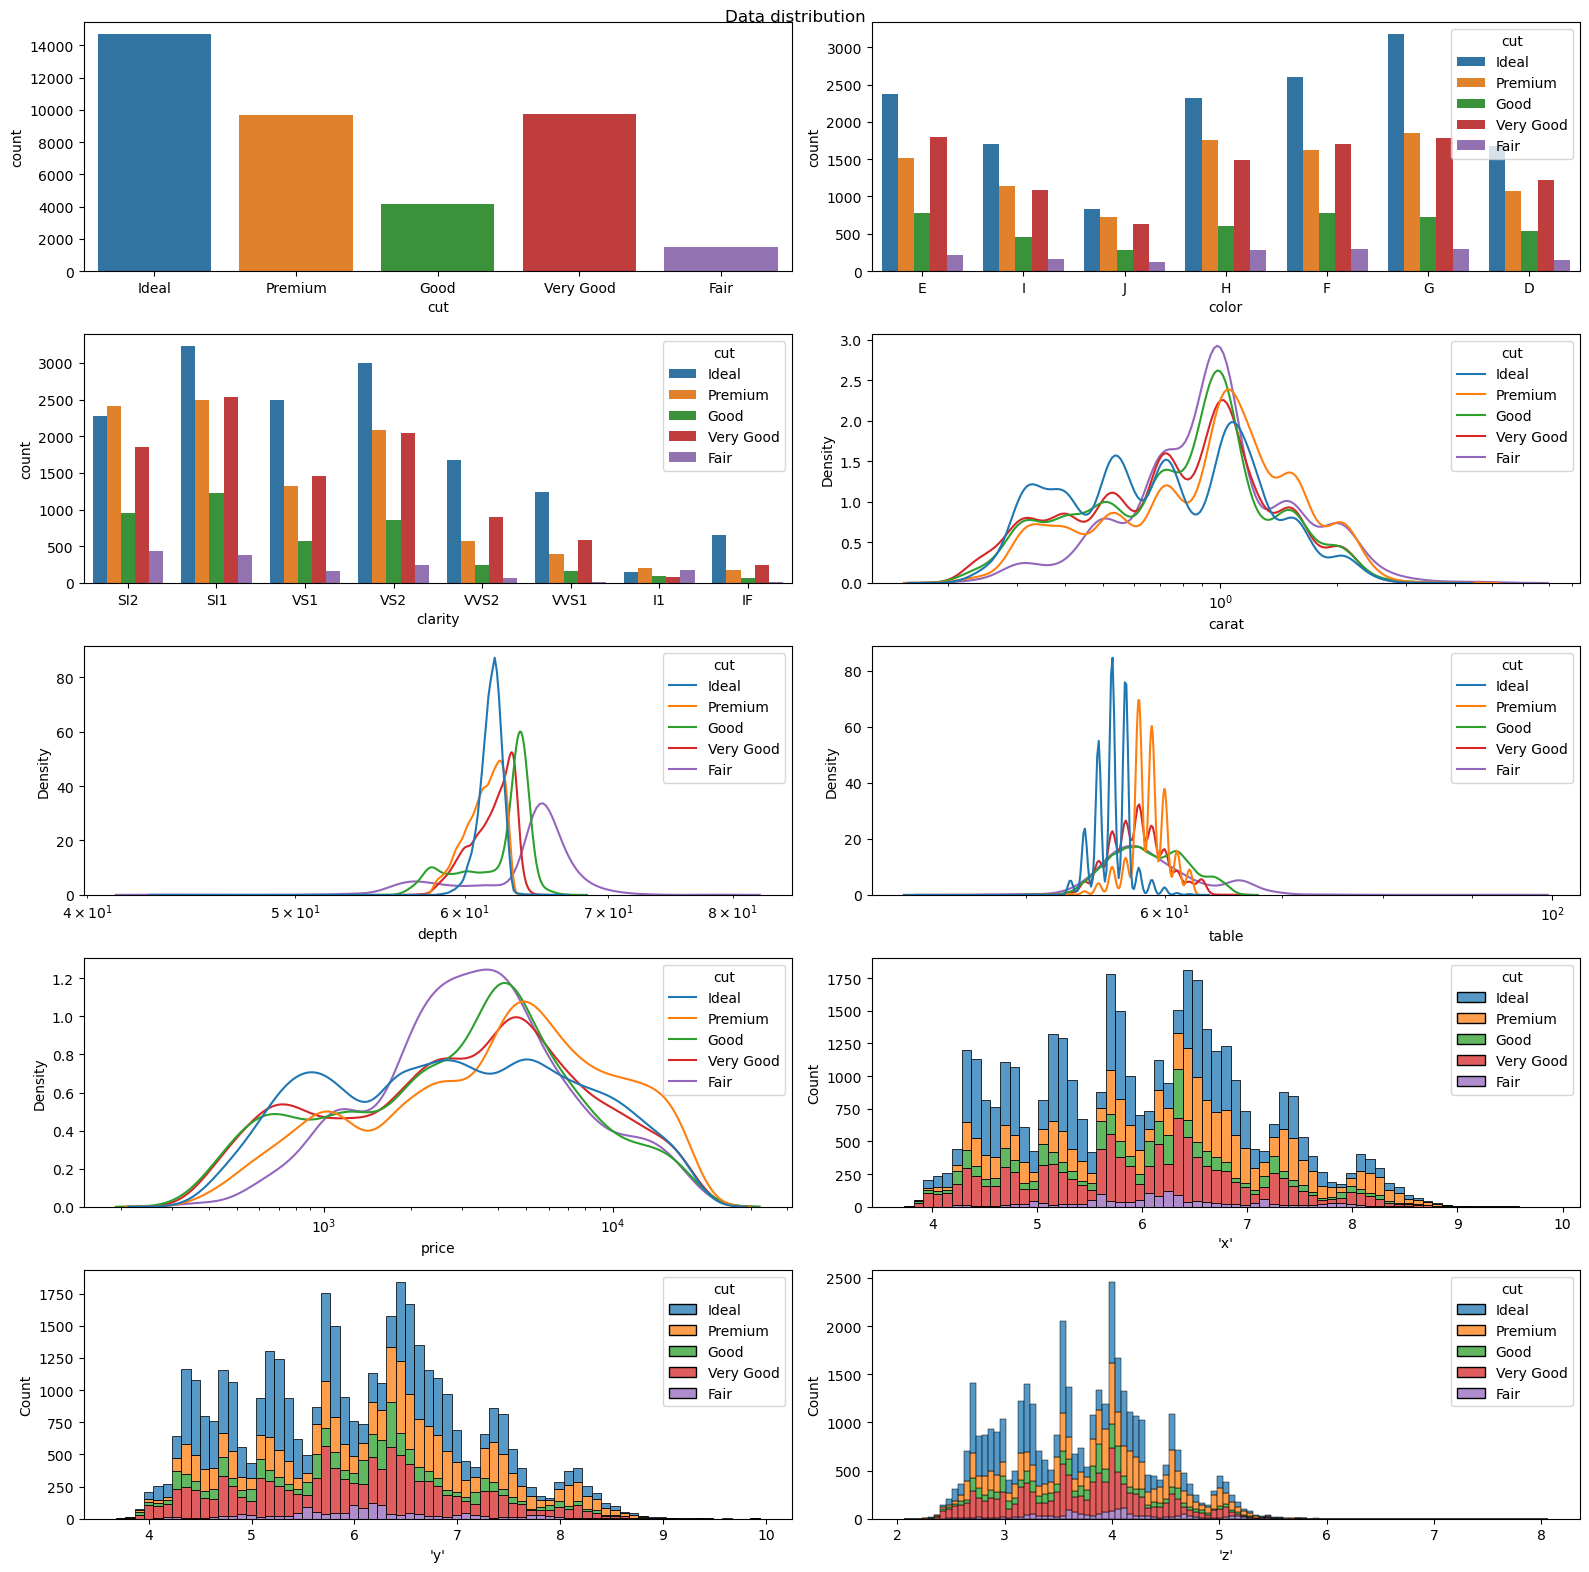

In [16]:
fig, axes = plt.subplots(5,2,figsize=(16,16))
fig.suptitle('Data distribution')

for ax,col in zip(axes.flatten(),cat_cols+num_cols):
    if col in num_cols:        
        if col not in ["'x'","'y'","'z'"]:
            sns.kdeplot(df, x=col, hue='cut', log_scale=True, ax=ax, common_norm=False)
        else:
            sns.histplot(df[(df[col] < 10) & (df[col] > 2)], x=col, hue='cut', ax=ax, common_norm=False, multiple="stack")
    else:
        sns.countplot(df,x=col, hue='cut', ax=ax)

plt.tight_layout()

## Price per categories

In [16]:
cat_cols

['cut', 'color', 'clarity']

In [17]:
temp = num_cols.copy()
temp.remove('price')

In [19]:
discrete_df = df[temp].apply(lambda x: pd.qcut(x,5))
discrete_df[['cut','price','clarity','color']]= df[['cut','price','clarity','color']]
discrete_df

,carat,depth,table,'x','y','z',cut,price,clarity,color
0,"(0.199, 0.45]","(60.7, 61.5]","(42.999, 56.0]","(-0.001, 4.92]","(-0.001, 4.93]","(-0.001, 3.03]",Ideal,326.0,SI2,E
1,"(0.199, 0.45]","(42.999, 60.7]","(59.0, 95.0]","(-0.001, 4.92]","(-0.001, 4.93]","(-0.001, 3.03]",Premium,326.0,SI1,E
2,"(0.199, 0.45]","(42.999, 60.7]","(59.0, 95.0]","(-0.001, 4.92]","(-0.001, 4.93]","(-0.001, 3.03]",Good,327.0,VS1,E
3,"(0.199, 0.45]","(62.1, 62.8]","(57.0, 58.0]","(-0.001, 4.92]","(-0.001, 4.93]","(-0.001, 3.03]",Premium,334.0,VS2,I
4,"(0.199, 0.45]","(62.8, 79.0]","(57.0, 58.0]","(-0.001, 4.92]","(-0.001, 4.93]","(-0.001, 3.03]",Good,335.0,SI2,J
...,...,...,...,...,...,...,...,...,...,...
53935,"(0.71, 1.01]","(60.7, 61.5]","(56.0, 57.0]","(5.72, 6.38]","(5.73, 6.38]","(3.03, 3.54]",Ideal,2757.0,SI1,D
53936,"(0.71, 1.01]","(62.8, 79.0]","(42.999, 56.0]","(4.92, 5.72]","(5.73, 6.38]","(3.54, 3.96]",Good,2757.0,SI1,D
53937,"(0.45, 0.71]","(62.1, 62.8]","(59.0, 95.0]","(4.92, 5.72]","(4.93, 5.73]","(3.54, 3.96]",Very Good,2757.0,SI1,D
53938,"(0.71, 1.01]","(60.7, 61.5]","(57.0, 58.0]","(5.72, 6.38]","(5.73, 6.38]","(3.54, 3.96]",Premium,2757.0,SI2,H


In [20]:
df[num_cols+['cut']].groupby(['cut']).agg(["median"])

,carat,depth,table,price,'x','y','z'
,median,median,median,median,median,median,median
cut,,,,,,,
Fair,1.00,64.9,58.0,3302.0,6.19,6.12,3.97
Good,0.90,63.3,59.0,3351.5,6.07,6.09,3.78
Ideal,0.72,61.8,56.0,2843.0,5.76,5.78,3.56
Premium,1.01,61.4,59.0,4364.0,6.45,6.41,3.95
Very Good,0.80,62.1,58.0,3267.0,5.95,5.98,3.70


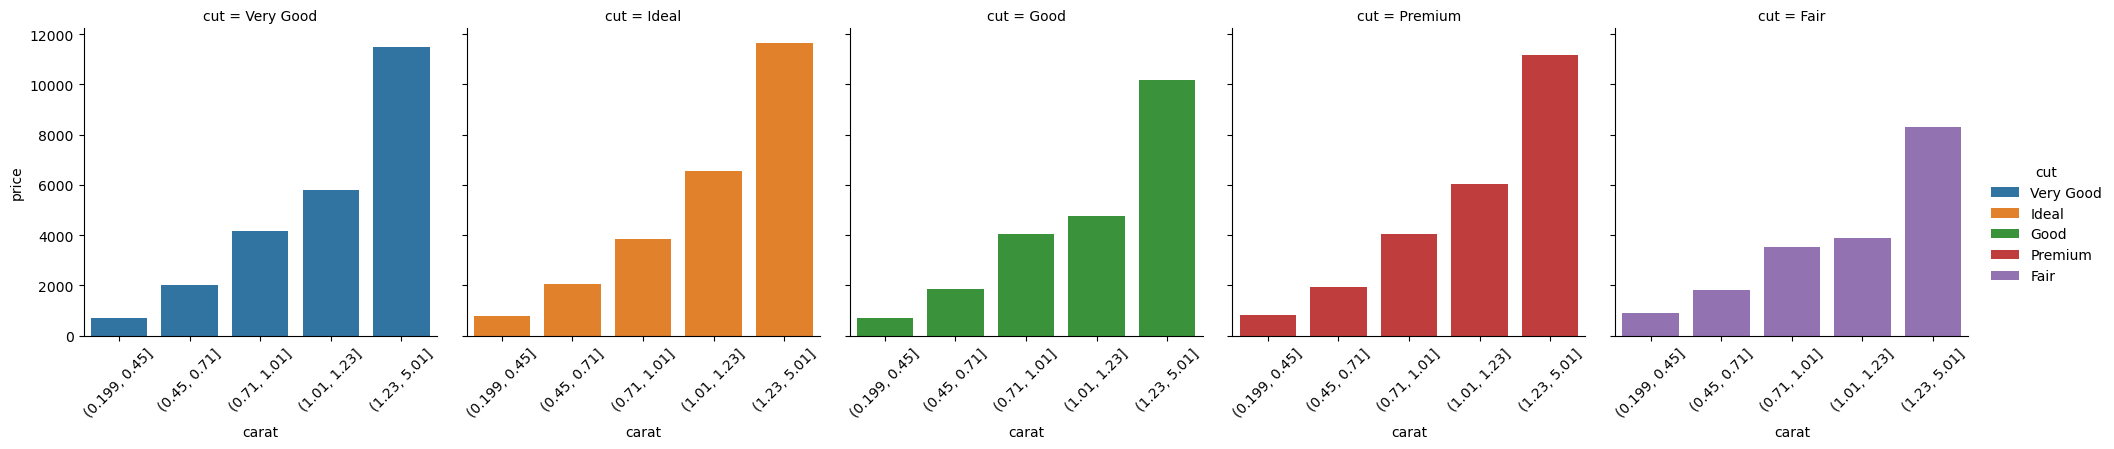

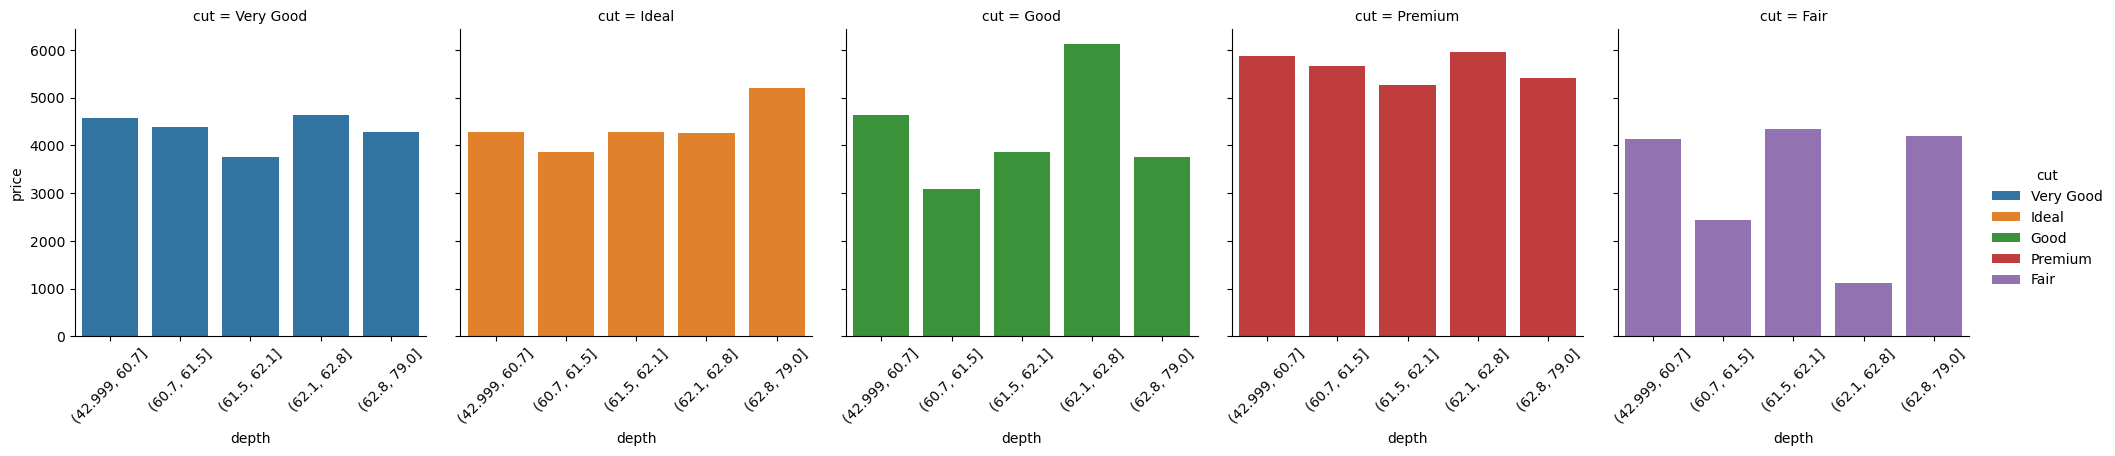

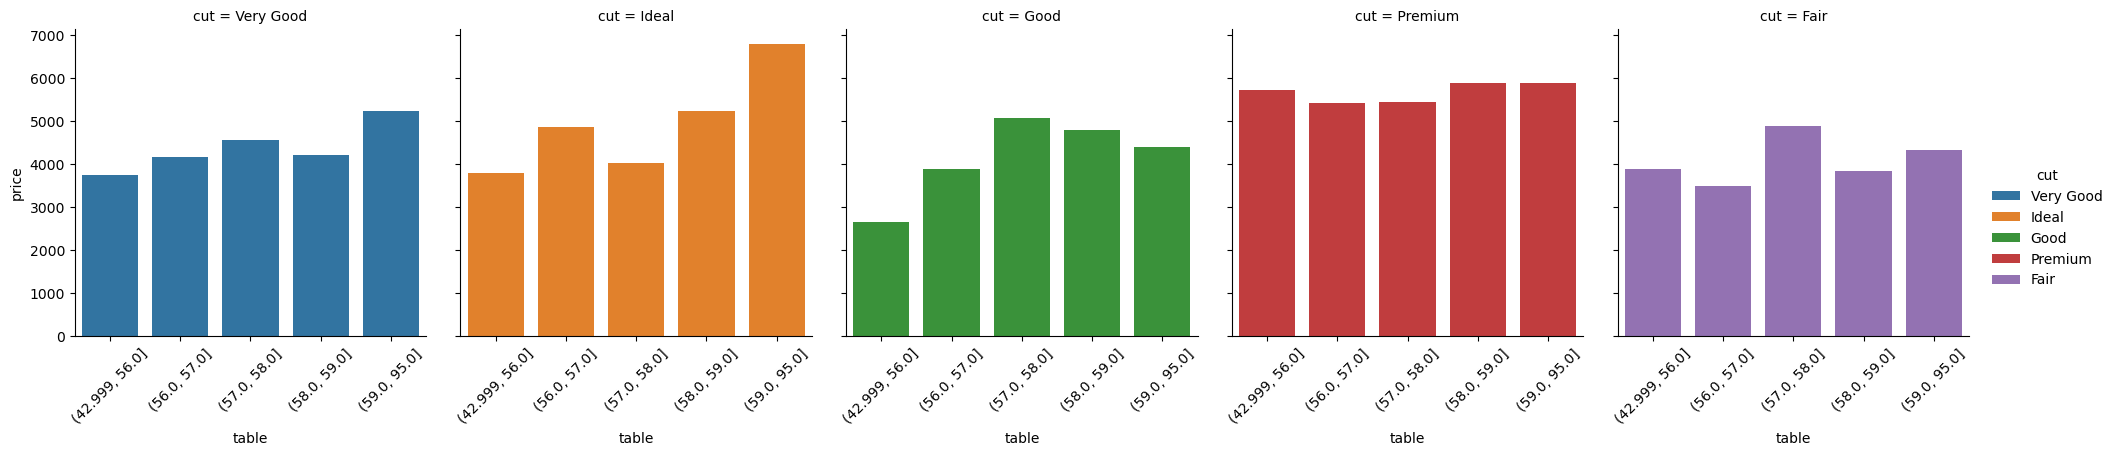

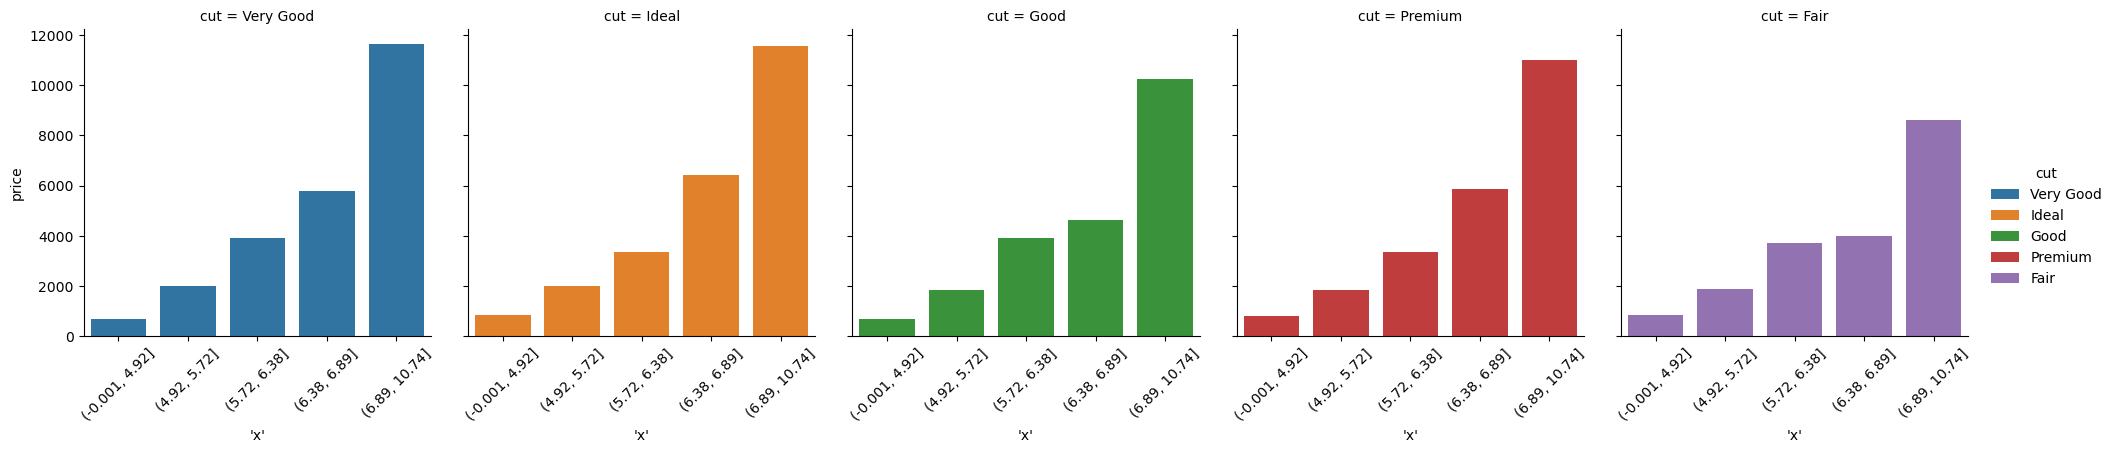

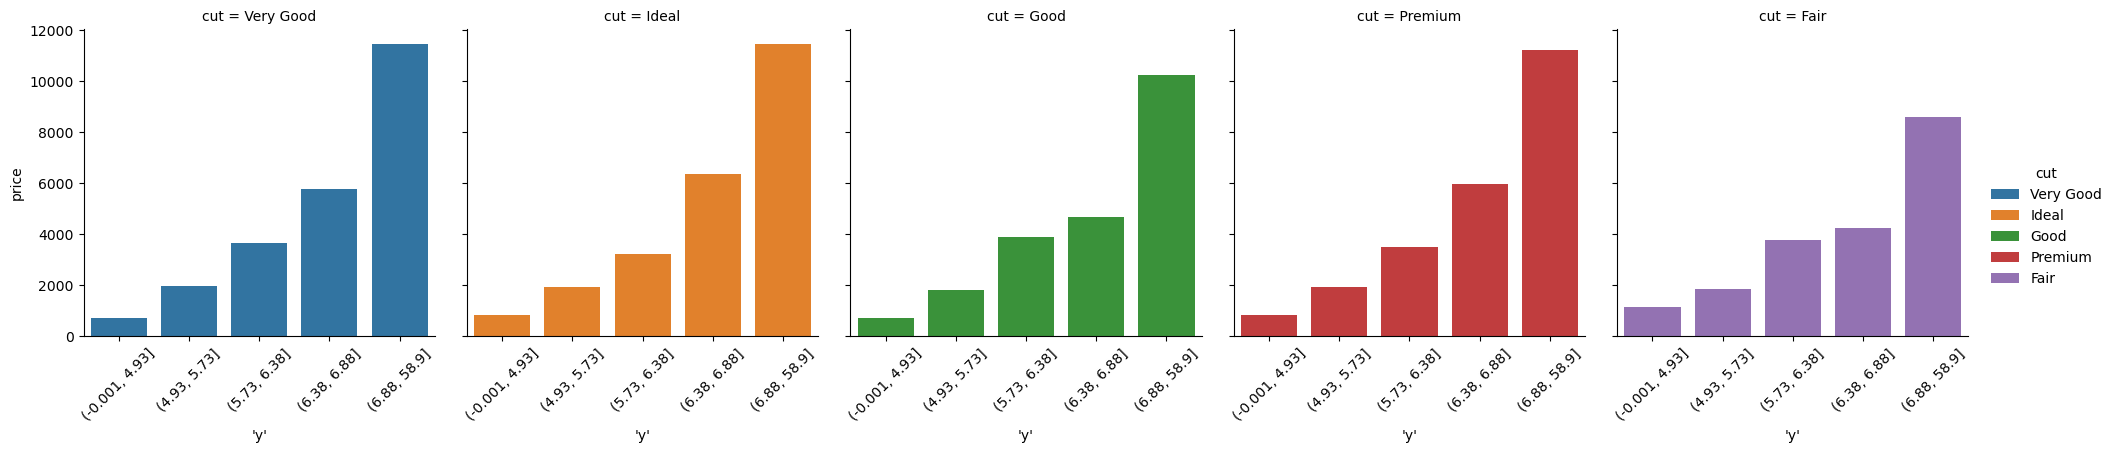

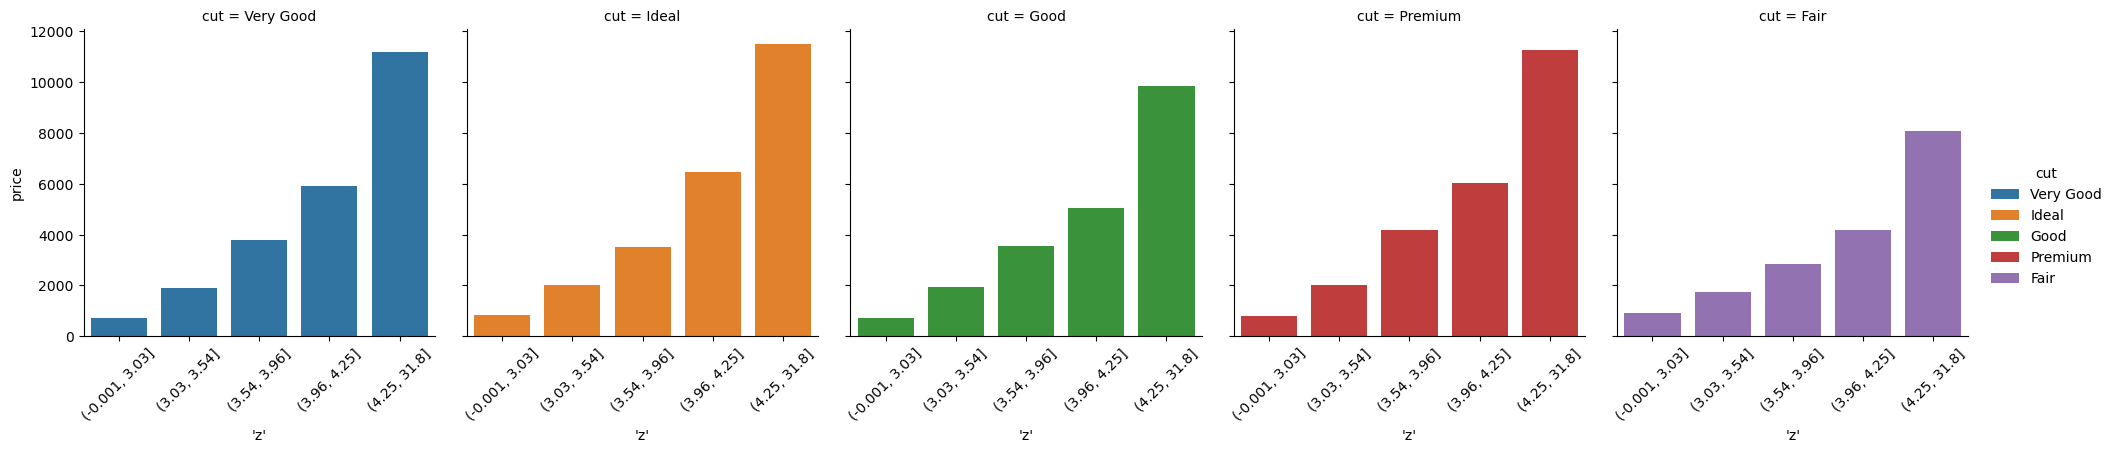

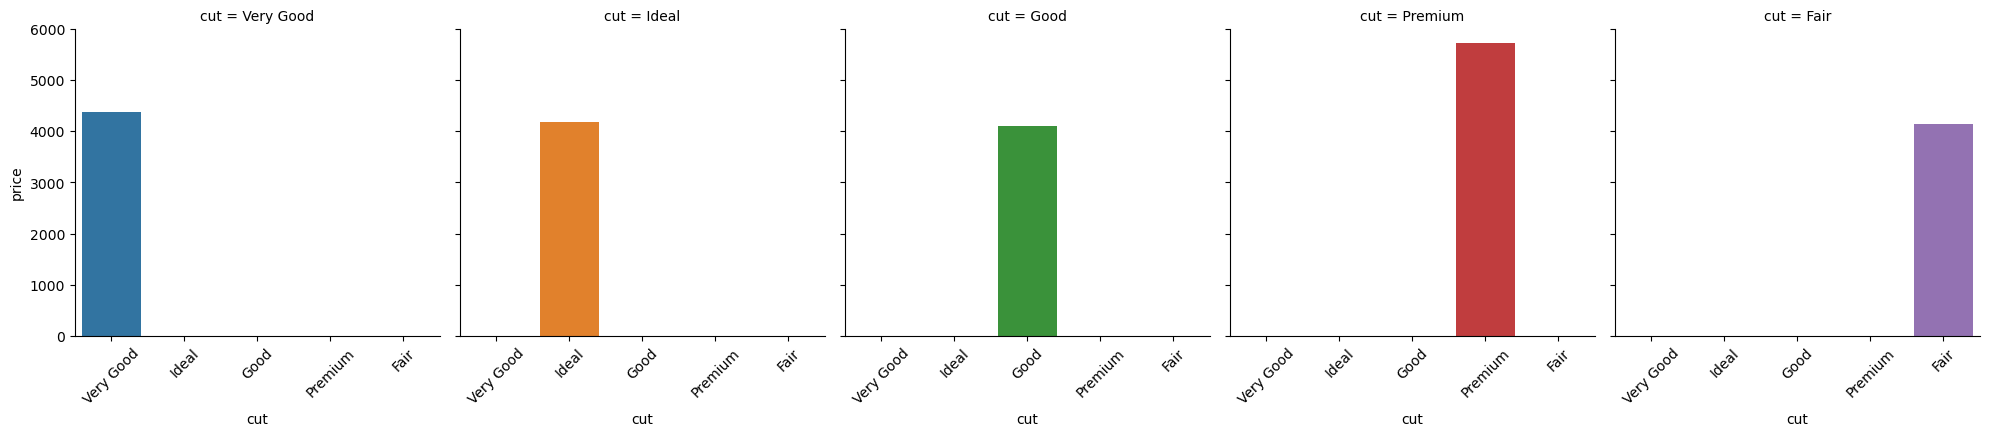

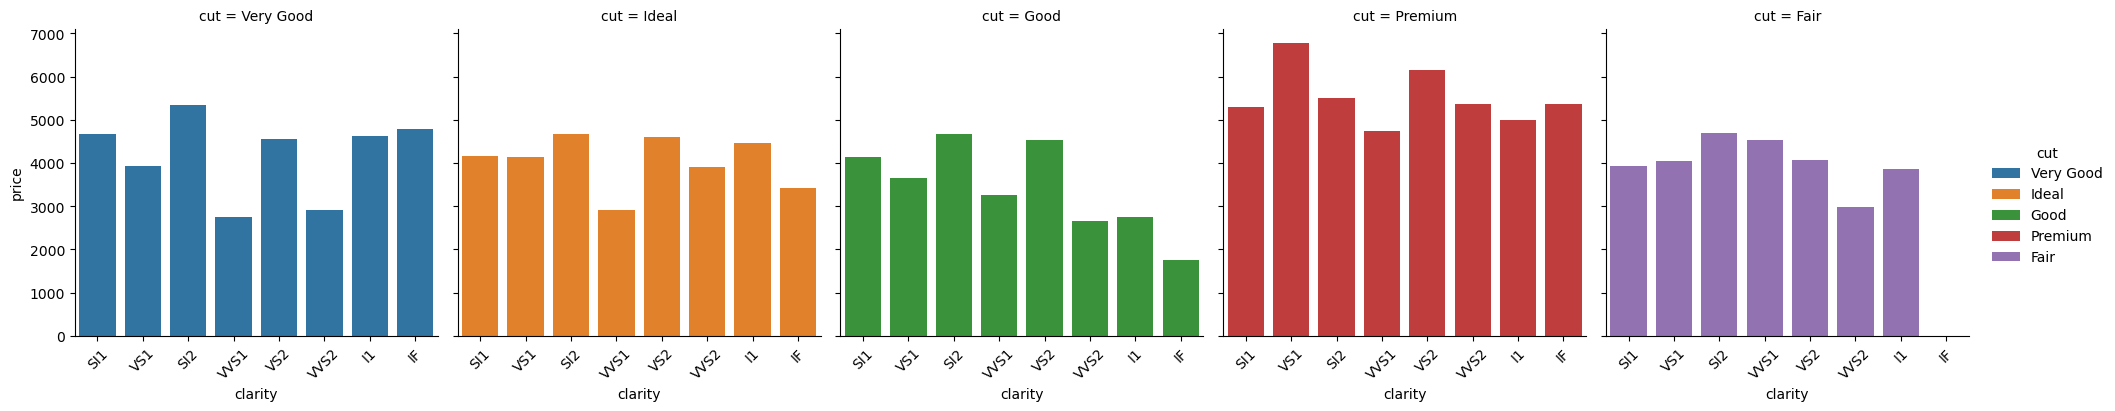

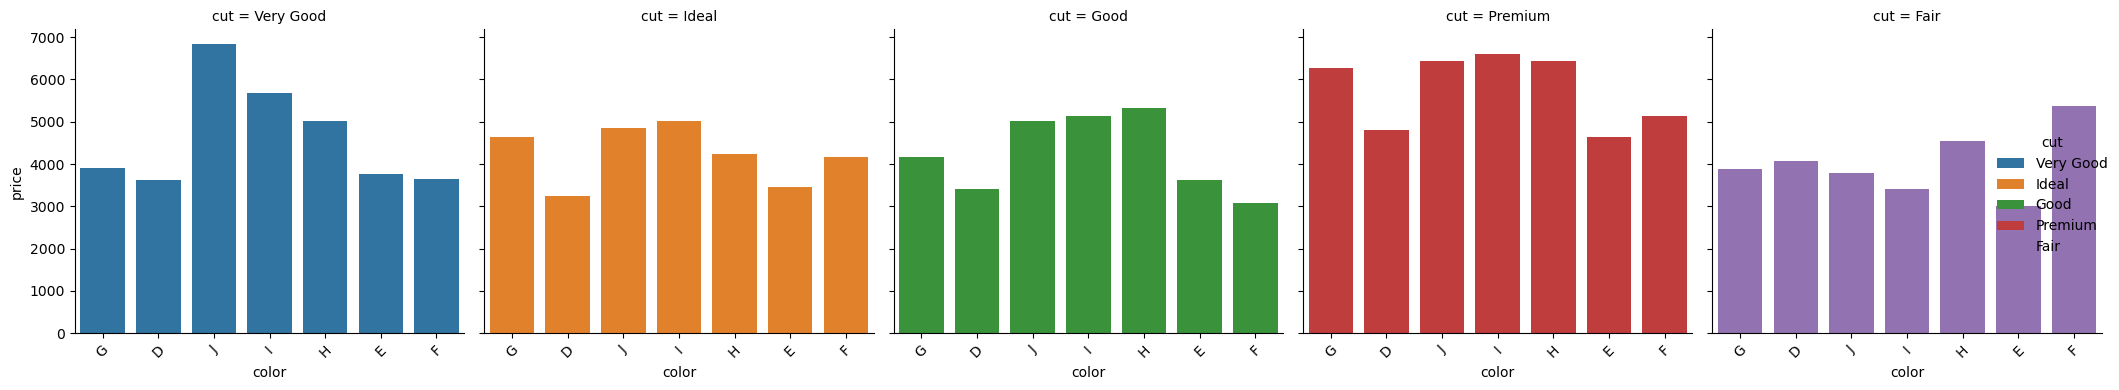

In [21]:
for col in list(discrete_df.columns):
    if col == 'price':
        continue
    sns.catplot(
    discrete_df.sample(frac=0.1,random_state=42), kind="bar",
    x=col, y="price", col="cut",
    height=4, aspect=1,
    errorbar=None, hue='cut'
            ).set_xticklabels(rotation=45)
       
plt.tight_layout()

### normalising based on carat

In [22]:
temp_df = discrete_df.copy()
temp_df['price per carat'] = df['price']/df['carat']

In [23]:
temp_df

,carat,depth,table,'x','y','z',cut,price,clarity,color,price per carat
0,"(0.199, 0.45]","(60.7, 61.5]","(42.999, 56.0]","(-0.001, 4.92]","(-0.001, 4.93]","(-0.001, 3.03]",Ideal,326.0,SI2,E,1417.391304
1,"(0.199, 0.45]","(42.999, 60.7]","(59.0, 95.0]","(-0.001, 4.92]","(-0.001, 4.93]","(-0.001, 3.03]",Premium,326.0,SI1,E,1552.380952
2,"(0.199, 0.45]","(42.999, 60.7]","(59.0, 95.0]","(-0.001, 4.92]","(-0.001, 4.93]","(-0.001, 3.03]",Good,327.0,VS1,E,1421.739130
3,"(0.199, 0.45]","(62.1, 62.8]","(57.0, 58.0]","(-0.001, 4.92]","(-0.001, 4.93]","(-0.001, 3.03]",Premium,334.0,VS2,I,1151.724138
4,"(0.199, 0.45]","(62.8, 79.0]","(57.0, 58.0]","(-0.001, 4.92]","(-0.001, 4.93]","(-0.001, 3.03]",Good,335.0,SI2,J,1080.645161
...,...,...,...,...,...,...,...,...,...,...,...
53935,"(0.71, 1.01]","(60.7, 61.5]","(56.0, 57.0]","(5.72, 6.38]","(5.73, 6.38]","(3.03, 3.54]",Ideal,2757.0,SI1,D,3829.166667
53936,"(0.71, 1.01]","(62.8, 79.0]","(42.999, 56.0]","(4.92, 5.72]","(5.73, 6.38]","(3.54, 3.96]",Good,2757.0,SI1,D,3829.166667
53937,"(0.45, 0.71]","(62.1, 62.8]","(59.0, 95.0]","(4.92, 5.72]","(4.93, 5.73]","(3.54, 3.96]",Very Good,2757.0,SI1,D,3938.571429
53938,"(0.71, 1.01]","(60.7, 61.5]","(57.0, 58.0]","(5.72, 6.38]","(5.73, 6.38]","(3.54, 3.96]",Premium,2757.0,SI2,H,3205.813953


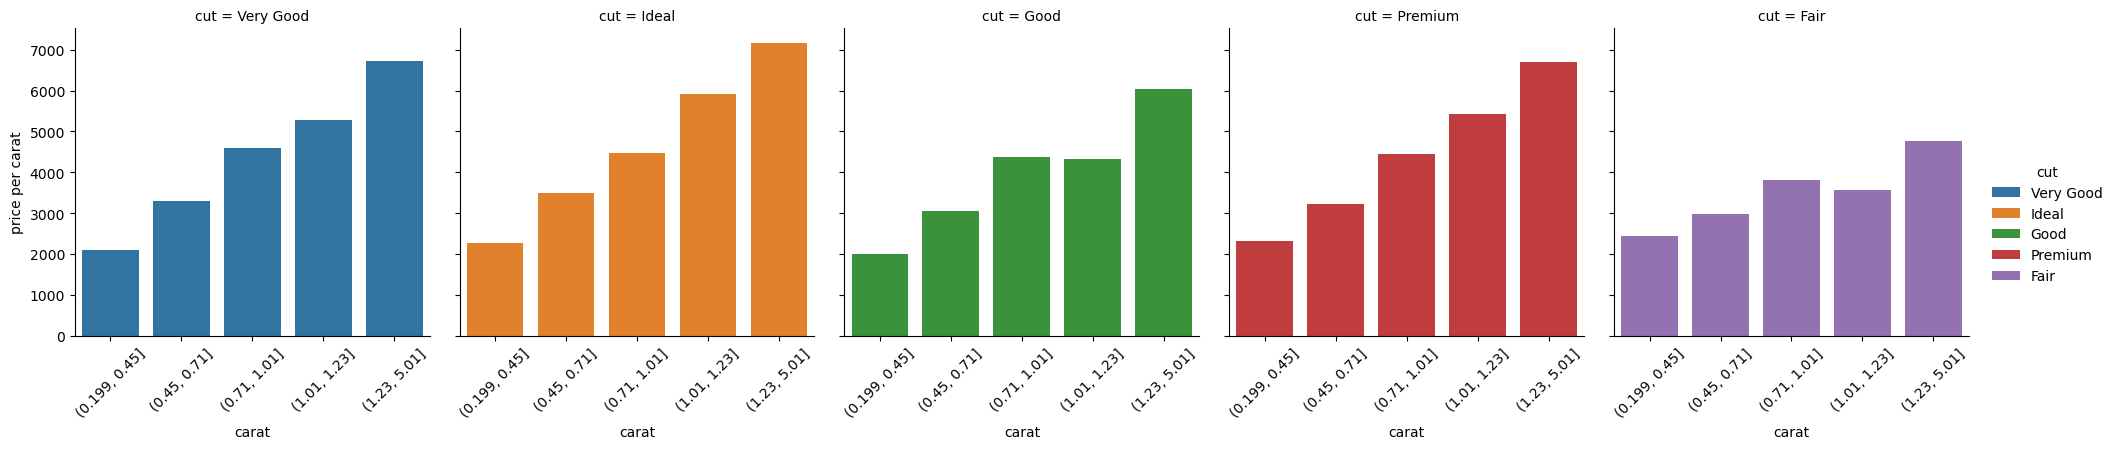

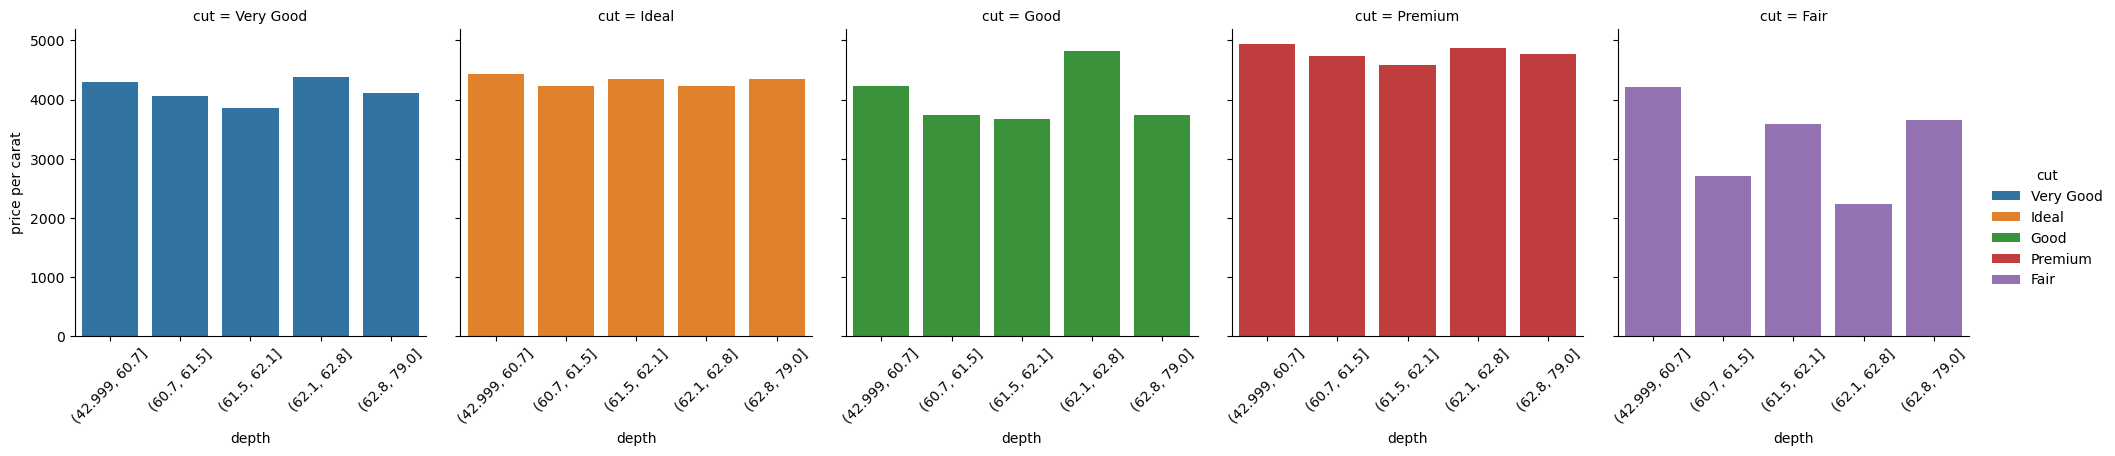

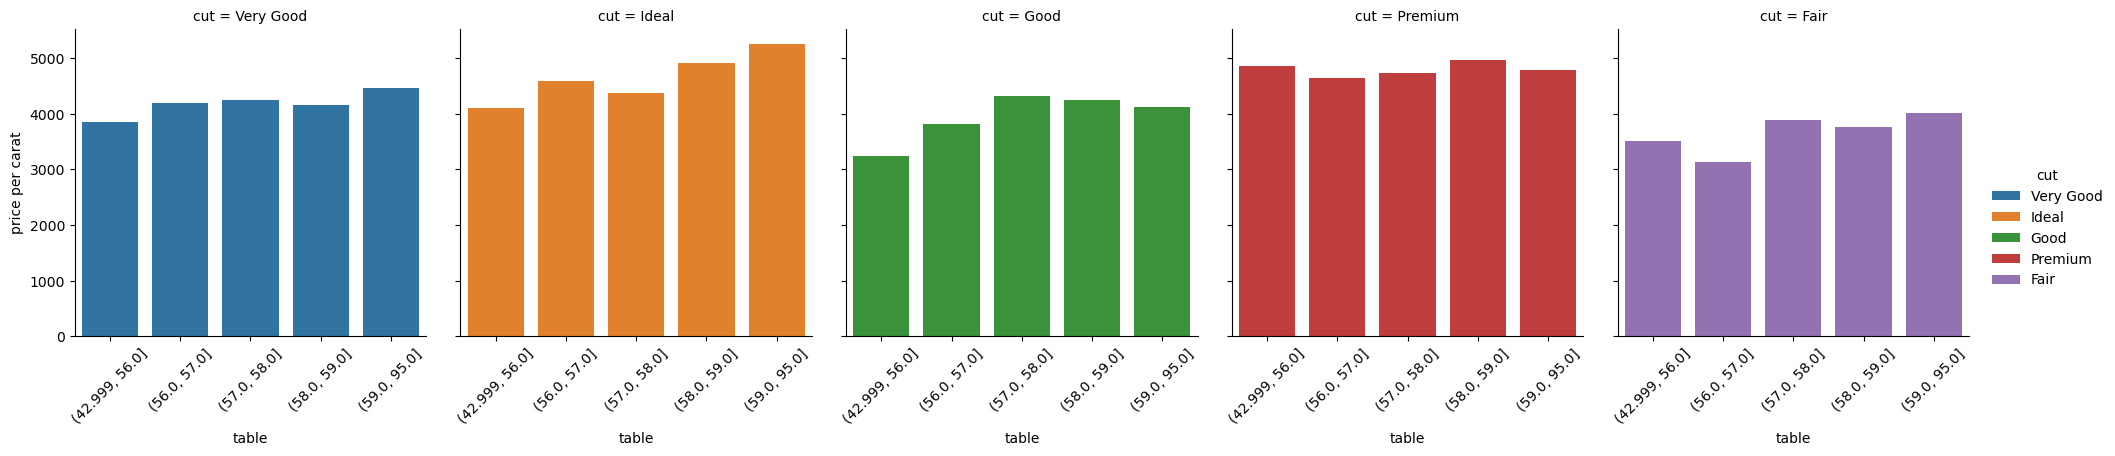

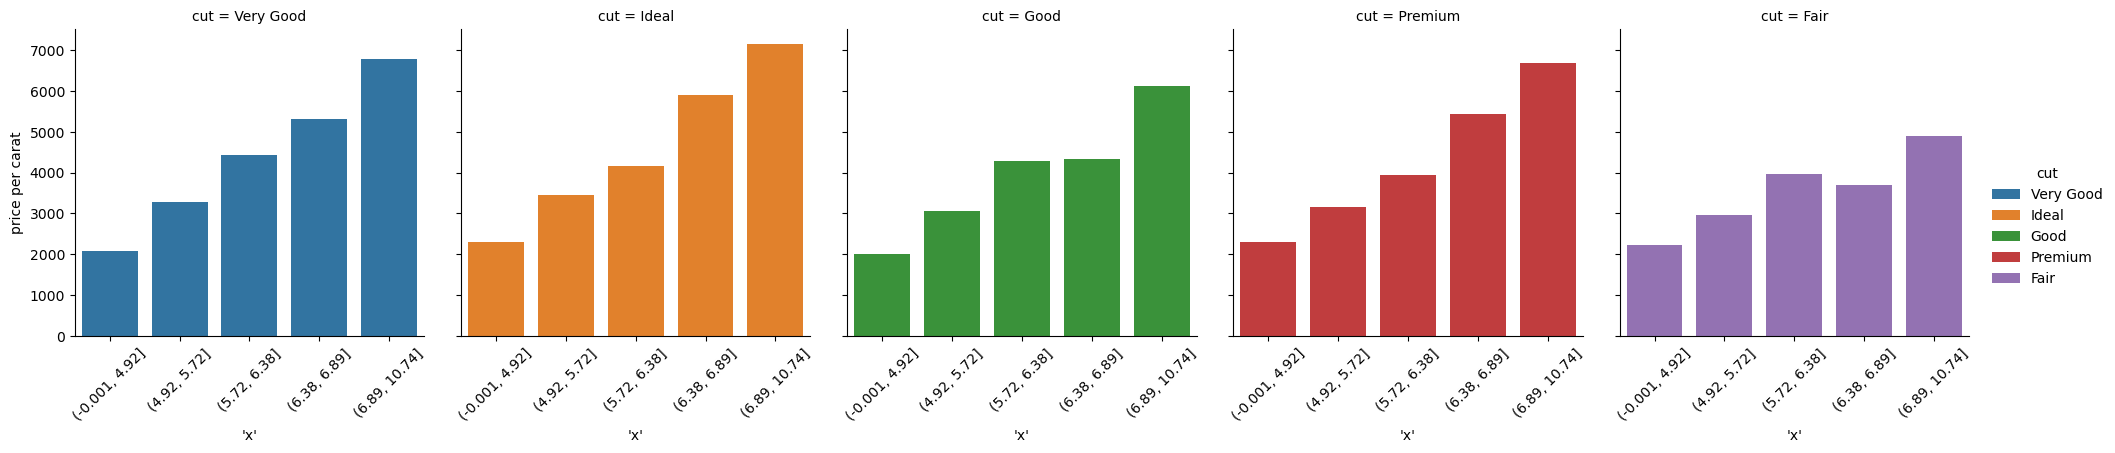

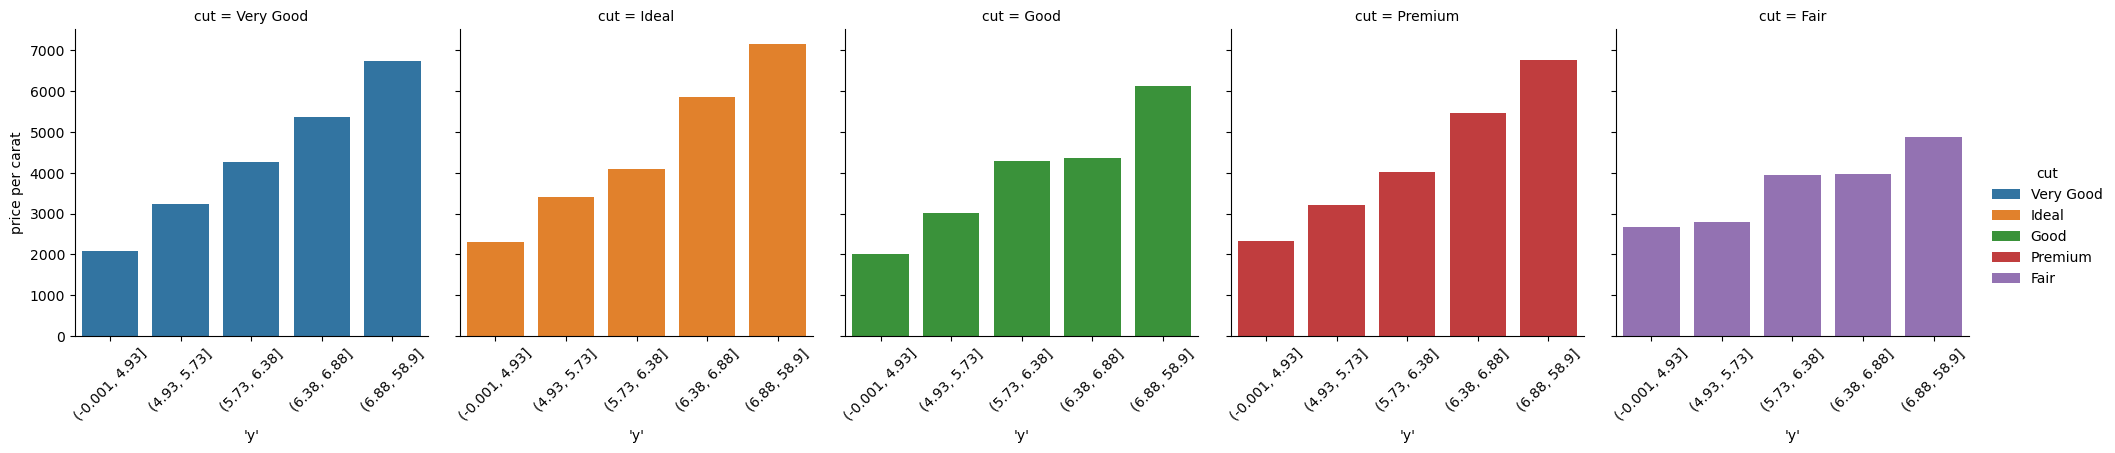

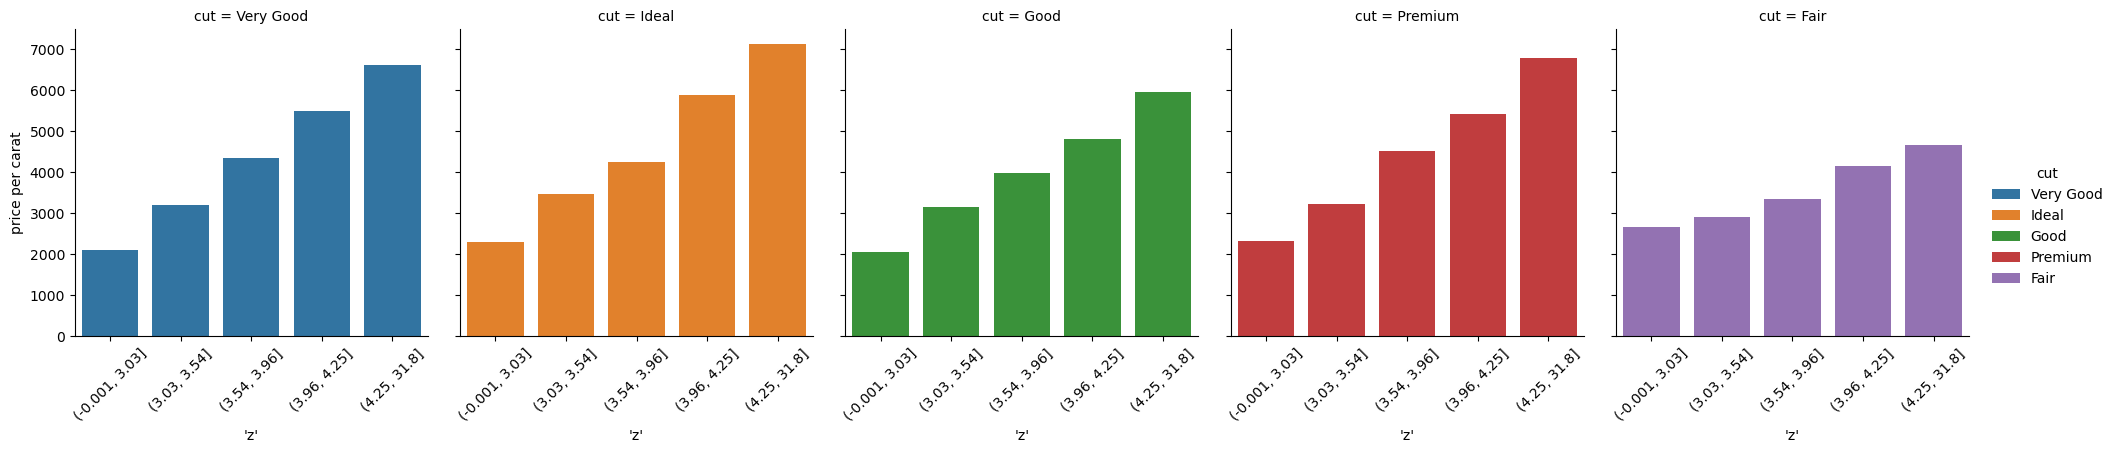

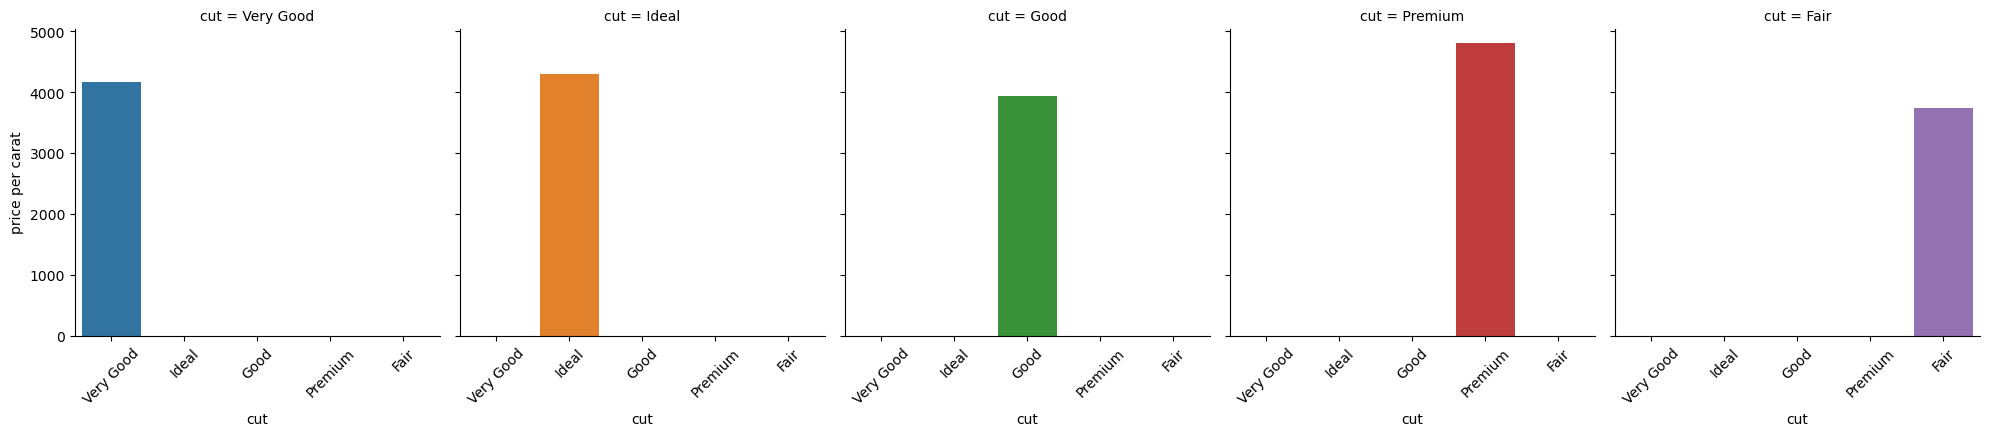

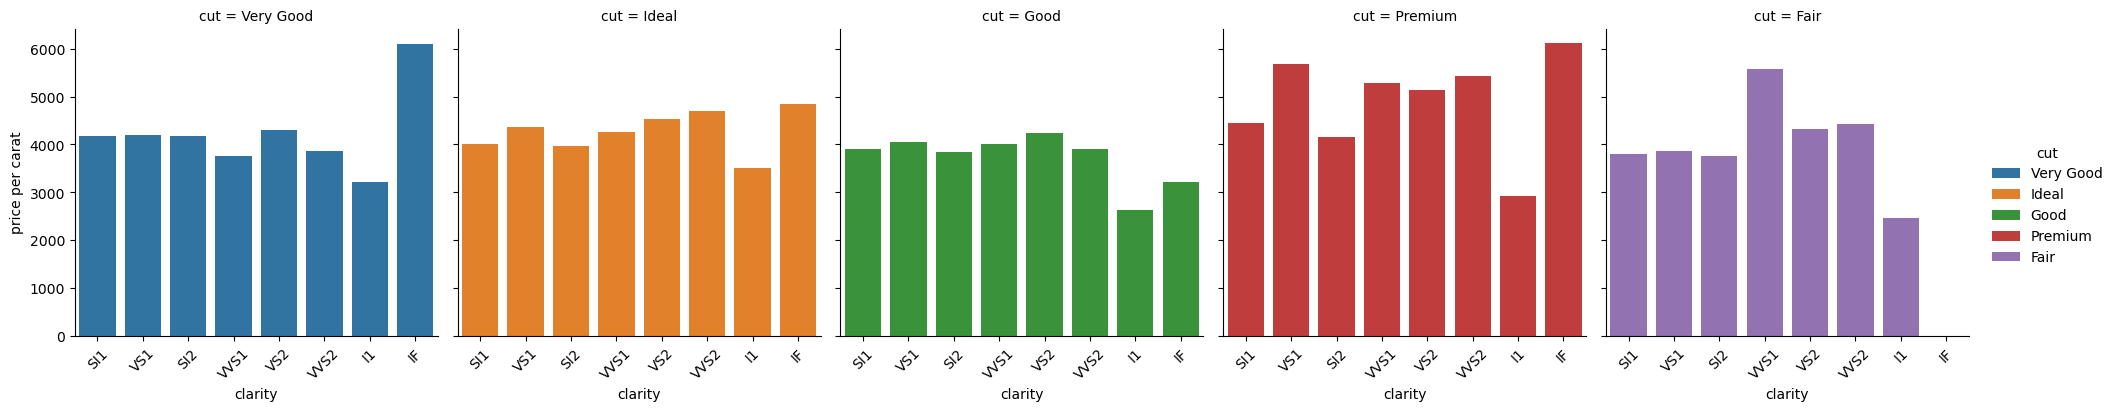

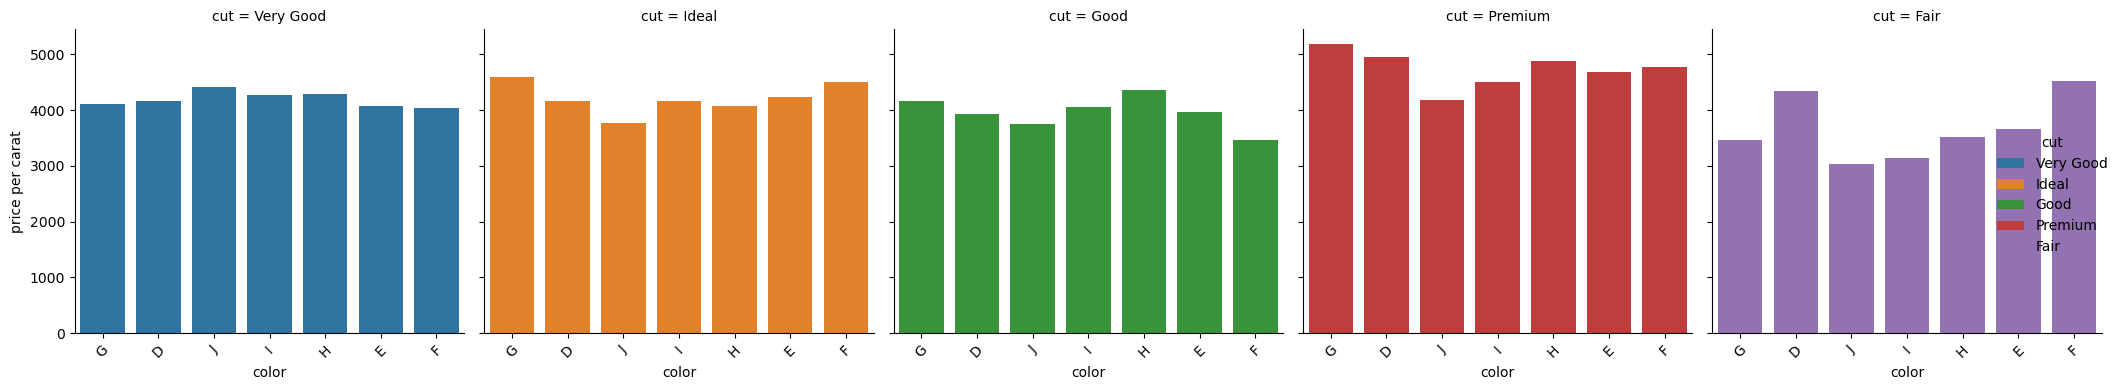

In [24]:
for col in list(discrete_df.columns):
    if col == 'price':
        continue
    sns.catplot(
    temp_df.sample(frac=0.1,random_state=42), kind="bar",
    x=col, y="price per carat", col="cut",
    height=4, aspect=1,
    errorbar=None, hue='cut'
            ).set_xticklabels(rotation=45)
       
plt.tight_layout()

# Corelation Plot

In [173]:
color_order = ["J", "I", "H", "G", "F", "E", "D"]
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

In [174]:
ord_enc = OrdinalEncoder(categories=[color_order,clarity_order])
cols_to_enc = [c for c in cat_cols if c != "cut"]
df[cols_to_enc] = ord_enc.fit_transform(df[cols_to_enc])


In [175]:
cols_to_enc

['color', 'clarity']

In [176]:
num_cols

['carat', 'depth', 'table', 'price', "'x'", "'y'", "'z'"]

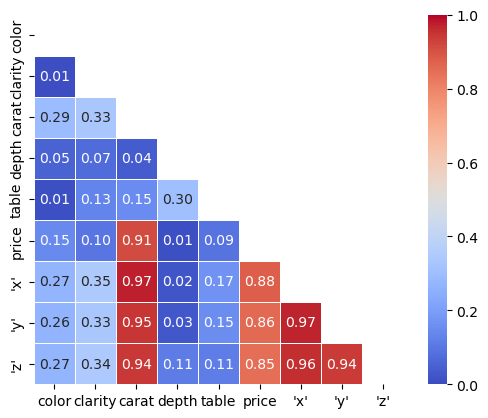

In [177]:
corr = df[cols_to_enc+num_cols].corr().abs()
mask = np.triu(np.ones_like(corr, dtype=bool))
masked_corr = corr.mask(mask)

axis_corr = sns.heatmap(
    masked_corr,
    vmin=0, vmax=1,
    cmap='coolwarm',
    square=True,
    annot=True,
    fmt='.2f',
    linewidths=0.5
)

In [178]:
threshold = 0.95
pairs = (masked_corr.stack().loc[lambda s: s > threshold].sort_values(ascending=False))
target_corr = df[num_cols].corrwith(df['cut']).abs()
to_drop = set()
for (a,b),r in pairs.items():
    if a in to_drop or b in to_drop:
        continue
    weaker = a if target_corr[a] < target_corr[b] else b
    to_drop.add(weaker)

In [179]:
to_drop

{"'x'"}

In [43]:
df = df.drop(columns=["'x'", "'z'", "'y'"])

In [180]:
df = df.drop(columns=to_drop)

In [181]:
df[cols_to_enc] = ord_enc.inverse_transform(df[cols_to_enc])

In [182]:
df

,carat,cut,color,clarity,depth,table,price,'y','z'
0,0.23,4.0,E,SI2,61.5,55.0,326.0,3.98,2.43
1,0.21,3.0,E,SI1,59.8,61.0,326.0,3.84,2.31
2,0.23,1.0,E,VS1,56.9,65.0,327.0,4.07,2.31
3,0.29,3.0,I,VS2,62.4,58.0,334.0,4.23,2.63
4,0.31,1.0,J,SI2,63.3,58.0,335.0,4.35,2.75
...,...,...,...,...,...,...,...,...,...
53935,0.72,4.0,D,SI1,60.8,57.0,2757.0,5.76,3.50
53936,0.72,1.0,D,SI1,63.1,55.0,2757.0,5.75,3.61
53937,0.70,2.0,D,SI1,62.8,60.0,2757.0,5.68,3.56
53938,0.86,3.0,H,SI2,61.0,58.0,2757.0,6.12,3.74


# Training

In [183]:
X = df.drop(columns=['cut'])
y = df['cut']

In [184]:
y

0        4.0
1        3.0
2        1.0
3        3.0
4        1.0
        ... 
53935    4.0
53936    1.0
53937    2.0
53938    3.0
53939    4.0
Name: cut, Length: 39756, dtype: float64

## Separating Validation set

In [185]:
X_train, X_val, y_train, y_val = train_test_split(
X, y, test_size=0.1, random_state=42, stratify=y)

In [186]:
X = X_train
y = y_train

In [187]:
df

,carat,cut,color,clarity,depth,table,price,'y','z'
0,0.23,4.0,E,SI2,61.5,55.0,326.0,3.98,2.43
1,0.21,3.0,E,SI1,59.8,61.0,326.0,3.84,2.31
2,0.23,1.0,E,VS1,56.9,65.0,327.0,4.07,2.31
3,0.29,3.0,I,VS2,62.4,58.0,334.0,4.23,2.63
4,0.31,1.0,J,SI2,63.3,58.0,335.0,4.35,2.75
...,...,...,...,...,...,...,...,...,...
53935,0.72,4.0,D,SI1,60.8,57.0,2757.0,5.76,3.50
53936,0.72,1.0,D,SI1,63.1,55.0,2757.0,5.75,3.61
53937,0.70,2.0,D,SI1,62.8,60.0,2757.0,5.68,3.56
53938,0.86,3.0,H,SI2,61.0,58.0,2757.0,6.12,3.74


## Pipeline

In [162]:
cat_cols = ['color','clarity']

In [31]:
cat_cols = cols_to_enc
num_cols =  ['carat', 'depth', 'table', 'price']

In [188]:
cat_cols = cols_to_enc
num_cols =  ["'y'","'z'",'carat','depth', 'table','price']

In [189]:
class IQRClipping(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.bounds_ = {}
        
    def fit(self, X, y=None):
        for col in X.columns:
            f_quart, t_quart = np.percentile(X[col],[25,75])
            iqr = t_quart - f_quart
            ub = t_quart + 1.5 * iqr
            lb = f_quart - 1.5 * iqr
            self.bounds_[col] = [lb,ub]
        return self

    def transform(self, X):
        X_temp = X.copy()
        for col in X.columns:
            if col in self.bounds_:
                lb,ub = self.bounds_[col]
                X_temp[col] = np.clip(X_temp[col],lb,ub)
        return X_temp
            
            

In [190]:
class IQRMasking(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.bounds_ = {}
        
    def fit(self, X, y=None):
        for col in X.columns:
            f_quart, t_quart = np.percentile(X[col],[25,75])
            iqr = t_quart - f_quart
            ub = t_quart + 1.5 * iqr
            lb = f_quart - 1.5 * iqr
            self.bounds_[col] = [lb,ub]
        return self

    def transform(self, X):
        X_temp = X.copy()
        mask_dict = {}
        for col in X.columns:
            if col in self.bounds_:
                lb,ub = self.bounds_[col]
                mask_dict[col] = (X_temp[col] < lb) | (X_temp[col] > ub)
        X_temp['is_outlier'] = pd.DataFrame(mask_dict).any(axis=1)
        return X_temp
            
            

In [191]:
def train_pipe(model,scalar=StandardScaler,remove_outlier=False):
    if scalar == None:
        scalar = ('scalar',"passthrough")
    else:
        scalar = ('scalar',scalar())
    if not remove_outlier:
        num_pipe = Pipeline([scalar])
    else:
        remove_outlier = ('outlier',remove_outlier())
        num_pipe = Pipeline([remove_outlier,scalar])

    cat_pipe = Pipeline([('hot_encoder', OneHotEncoder())])
    preprocessor = ColumnTransformer(
        [
            ('cat',cat_pipe, cat_cols),
            ('num',num_pipe, num_cols)
        ]
    )
    train_pipe = Pipeline(
        [
            ('prep',preprocessor),
            ('model', model)
        ]
    )
    return train_pipe

In [192]:
def training(train_pipe, scorer=None):
    cv_results = cross_validate(train_pipe, X, y, cv=5, return_train_score=True, scoring=scorer, return_estimator=True)
    return cv_results
       

### Hypertuner function with optuna

In [44]:
def hypertuner(train_pipe,n_trials=100):
    def objective(trial):
        params = {
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 200, 800),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 10, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
            }
        train_pipe['model'].set_params(**params)
    
        cv_results = training(train_pipe, qks)
    
        score = cv_results['test_score'].mean()
        print(f'Train_score:{cv_results['train_score'].mean()}')
        return score  # An objective value linked with the Trial object.

    study = optuna.create_study(direction="maximize")  # Create a new study.
    study.optimize(objective, n_trials=n_trials)  # Invoke optimization of the objective function.

### Logistic regression

#### Without Outlier removal and StandardScaling

In [223]:
log_pipe = train_pipe(LogisticRegression(),remove_outlier=IQRMasking)

In [224]:
cv_results = training(log_pipe)

In [ ]:
cols = list(cv_results['estimator'][0]['prep']['cat']['hot_encoder'].get_feature_names_out())+num_cols

In [117]:
coeffs = pd.DataFrame(data=cv_results['estimator'][0]['model'].coef_,columns=cols).agg(['mean','std']).T


In [225]:
results = f'{cv_results['test_score'].mean()}+-{cv_results['test_score'].std()}'

In [226]:
results

'0.5729737283398547+-0.008454339881746068'

In [227]:
log_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

#### With RobustScaling

In [228]:
log_pipe = train_pipe(LogisticRegression(),scalar=RobustScaler, remove_outlier=IQRMasking)
cv_results = training(log_pipe)
# coeffs = pd.DataFrame(data=cv_results['estimator'][0]['model'].coef_,columns=cols).agg(['mean','std']).T
results = f'{cv_results['test_score'].mean()}+-{cv_results['test_score'].std()}'

In [229]:
results

'0.5728060368921184+-0.008479986269205549'

In [230]:
log_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

 With RobustScaling: <br>
         outlier_yes:'0.5637506987143656+-0.005894035667493394' <br>
         outlier_no :'0.5656512017887088+-0.007547874668063564' <br>
         outlier_masking:'0.5728060368921184+-0.008479986269205549'<br>

 With StandardScalar: <br>
         outlier_yes:'0.5637506987143656+-0.005639382469167062'<br>
         outlier_no :'0.5656512017887088+-0.007547874668063564'<br>
         outlier_masking:'0.5729737283398547+-0.008454339881746068'<br>


### XGBOOST

In [193]:
scores = {
       "qks":make_scorer(cohen_kappa_score, weights="quadratic"),
        "f1":"f1_macro"
}


In [194]:
xgb_pipe = train_pipe(XGBClassifier(),remove_outlier=IQRMasking,scalar=None)
cv_results = training(xgb_pipe, scores)

In [195]:
qks_results = f'{cv_results['test_qks'].mean()}+-{cv_results['test_qks'].std()}'
f1_results = f'{cv_results['test_f1'].mean()}+-{cv_results['test_f1'].std()}'

In [196]:
xgb_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

In [197]:
qks_results, f1_results

('0.7868047633133168+-0.0021052205592752755',
 '0.7347958893141581+-0.0039758198078788266')

 With RobustScaling: <br>
         outlier_yes:
                   qks:(('0.773371619352907+-0.003377901725632658',
                     f1:'0.7099962881545605+-0.007242960720480314')<br>
         outlier_no :
                     qks:('0.7616402455985225+-0.0038721052231248053',
                      f1: 0.6847708560567553+-0.00505363622364797')<br>
        outlier_masking:
                     ('0.7714331051422008+-0.005515660003738091',
                     '0.7080201840777585+-0.007844640348551273')<br>

 With StandardScalar: <br>
         outlier_yes:
                     qks:('0.773371619352907+-0.003377901725632658',
                     f1:'0.7099962881545605+-0.007242960720480314')<br>
         outlier_no :
                     qks:('0.7616402455985225+-0.0038721052231248053',
                      f1: '0.6847708560567553+-0.00505363622364797')<br>
        outlier_masking:
                    ('0.7714331051422008+-0.005515660003738091',
                     '0.7080201840777585+-0.007844640348551273')<br>
        
 with passthrough:
         outlier_masking:('0.7714331051422008+-0.005515660003738091',
                         '0.7080201840777585+-0.007844640348551273')<br>
        corelated_actual_removal:('0.7740930115295547+-0.0033402554791682184',
                         '0.7108424888367135+-0.004851503223049982')<br>
            non_removal:('0.8114241014170991+-0.0038439930382876586',
                         '0.7730762376334989+-0.004653219524986112')<br>
            higher_threshold_removal:('0.7868047633133168+-0.0021052205592752755',
 '0.7347958893141581+-0.0039758198078788266')

#### HyperTUNING


In [73]:
hypertuner(xgb_pipe)

[I 2026-11-09 18:58:47,220] A new study created in memory with name: no-name-ab0bdf5c-7ba3-4de3-ac57-603f29cbb486
[I 2026-11-09 18:59:07,942] Trial 0 finished with value: 0.7348526792303938 and parameters: {'max_depth': 5, 'learning_rate': 0.020047960044878917, 'n_estimators': 299, 'subsample': 0.9586527379147433, 'colsample_bytree': 0.9111524042216996, 'min_child_weight': 7, 'gamma': 3.3156543387854684, 'reg_lambda': 0.021778979303712493, 'reg_alpha': 0.09233802512206207}. Best is trial 0 with value: 0.7348526792303938.


Train_score:0.7375562384494316


[I 2026-11-09 18:59:49,974] Trial 1 finished with value: 0.7398209638594591 and parameters: {'max_depth': 10, 'learning_rate': 0.024382274292844685, 'n_estimators': 756, 'subsample': 0.6990248025651076, 'colsample_bytree': 0.7726641477637843, 'min_child_weight': 10, 'gamma': 4.215073110472198, 'reg_lambda': 0.042205511084821186, 'reg_alpha': 0.1710515928845639}. Best is trial 1 with value: 0.7398209638594591.


Train_score:0.741472988665523


[I 2026-11-09 19:00:20,446] Trial 2 finished with value: 0.7542321999271523 and parameters: {'max_depth': 4, 'learning_rate': 0.10238764044738238, 'n_estimators': 604, 'subsample': 0.795255372033061, 'colsample_bytree': 0.8198311723816204, 'min_child_weight': 4, 'gamma': 3.7895177953494525, 'reg_lambda': 0.7129705298035786, 'reg_alpha': 0.0034297150820463934}. Best is trial 2 with value: 0.7542321999271523.


Train_score:0.7572024467079068


... (190 outputs left out)

[I 2026-11-09 19:52:13,705] Trial 98 finished with value: 0.7634931393071183 and parameters: {'max_depth': 10, 'learning_rate': 0.28242949640887205, 'n_estimators': 613, 'subsample': 0.8725934595491938, 'colsample_bytree': 0.9653474233908091, 'min_child_weight': 12, 'gamma': 0.6894792706436979, 'reg_lambda': 0.01420031443354355, 'reg_alpha': 0.02288063730411625}. Best is trial 96 with value: 0.764024312068772.


Train_score:0.7815552129024853


[I 2026-11-09 19:52:48,795] Trial 99 finished with value: 0.7618724650097669 and parameters: {'max_depth': 9, 'learning_rate': 0.21409524703127406, 'n_estimators': 626, 'subsample': 0.859391537697069, 'colsample_bytree': 0.9638266294301443, 'min_child_weight': 13, 'gamma': 0.7458400621755744, 'reg_lambda': 0.014558652252734327, 'reg_alpha': 0.007370704248373951}. Best is trial 96 with value: 0.764024312068772.


Train_score:0.7800545289283382
